In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib import rc
from matplotlib.ticker import ScalarFormatter

import seaborn as sns

import torch
from numpy.linalg import inv
from numpy.linalg import det
from numpy import log, prod, absolute, exp, pi, trace, dot, cumsum, \
                  hstack, ix_, sqrt, eye, diag, array, sum

In [2]:
def generate_mean_cov(M,cov_val):
    m1 = torch.zeros(M)
    cov1 = torch.zeros(M,M)
    i, j = torch.triu_indices(M,M)
    cov1[i, j] = cov_val
    cov1.T[i,j] = cov_val
    cov1.fill_diagonal_(1)
    
    m2 = torch.zeros(M)
    cov2 = torch.zeros(M,M)
    cov2.fill_diagonal_(1)
    return m1,cov1,m2,cov2

def cal_HSIC(m1,m2,cov1,cov2,gamma):
    dim = len(m1)
    gam = 4/gamma
    k3 = 1 / sqrt(absolute(det(gam * cov1 + gam * cov2 + eye(dim))))
    k1 = 1 / sqrt(absolute(det(gam * cov1 + gam * cov1 + eye(dim))))
    k2 = 1 / sqrt(absolute(det(gam * cov2 + gam * cov2 + eye(dim))))
    d = k1 + k2 - 2 * k3
    return d

In [3]:
nodes = [100,300,500,700,900,1100,1300,1500,1700,1900,2100,2300,2500,2700,3000]

In [ ]:
gcor0 = pd.read_csv("./GHSIC_code/new_results/exp-1E/gcor_gamma_c0_hathatd_fast.csv")
del gcor0['Unnamed: 0']
gcor0.head()

,0,1,2,3,4,5,6,7,8,9,...,40,41,42,43,44,45,46,47,48,49
0,0.048849,0.000885,0.038139,0.040381,0.043508,0.042488,0.002393,0.001371,0.002867,0.044586,...,0.046898,0.044779,0.000847,0.037388,0.040787,0.001075,0.002586,0.001542,0.001741,0.036642
1,0.042853,0.037267,0.040925,0.041466,0.040507,0.042652,0.037097,0.040144,0.039839,0.042022,...,0.039128,0.050854,0.038253,0.039846,0.039554,0.039295,0.036617,0.041323,0.035773,0.038658
2,0.040860,0.038473,0.039235,0.041084,0.040887,0.042698,0.038179,0.039881,0.043248,0.041786,...,0.042812,0.047104,0.036258,0.041304,0.042329,0.042005,0.040021,0.045129,0.038741,0.042217
3,0.041074,0.039022,0.039624,0.039169,0.040171,0.045375,0.041836,0.041923,0.042897,0.041426,...,0.042472,0.046292,0.036696,0.039964,0.044263,0.041834,0.039665,0.045179,0.039648,0.039746
4,0.040914,0.041872,0.039852,0.040208,0.042402,0.045338,0.043327,0.040616,0.041648,0.041605,...,0.044416,0.055299,0.035941,0.042199,0.045126,0.040743,0.039951,0.043223,0.039978,0.040944


In [ ]:
gcor1 = pd.read_csv("./GHSIC_code/new_results/exp-1E/gcor_gamma_c2_hathatd_fast.csv")
del gcor1['Unnamed: 0']
gcor1.head()

,0,1,2,3,4,5,6,7,8,9,...,40,41,42,43,44,45,46,47,48,49
0,0.054437,0.036367,0.044402,0.042283,0.050813,0.052551,0.033585,0.044050,0.043188,0.047787,...,0.057281,0.052048,0.031084,0.054113,0.046044,0.035823,0.039706,0.043743,0.042576,0.048560
1,0.049672,0.045409,0.049345,0.046934,0.048209,0.048196,0.047693,0.049743,0.049246,0.048206,...,0.048073,0.058680,0.046281,0.051190,0.045081,0.044813,0.045159,0.049541,0.041003,0.044768
2,0.047212,0.045975,0.046655,0.047002,0.048097,0.050013,0.046903,0.047368,0.053153,0.049122,...,0.052028,0.055870,0.044241,0.052005,0.050338,0.049393,0.048686,0.052222,0.047336,0.050522
3,0.048471,0.047761,0.047202,0.046648,0.048025,0.053531,0.049652,0.049200,0.053863,0.048349,...,0.050700,0.055838,0.044351,0.049587,0.052638,0.050350,0.049293,0.053809,0.046816,0.048393
4,0.048745,0.050640,0.047348,0.047277,0.049430,0.053585,0.051316,0.048677,0.051574,0.048524,...,0.053136,0.056244,0.044202,0.052206,0.053358,0.049051,0.049436,0.052522,0.047053,0.049669


In [ ]:
gcor2 = pd.read_csv("./GHSIC_code/new_results/exp-1E/gcor_gamma_c4_hathatd_fast.csv")
del gcor2['Unnamed: 0']
gcor2.head()

,0,1,2,3,4,5,6,7,8,9,...,40,41,42,43,44,45,46,47,48,49
0,0.053301,0.035037,0.045485,0.042295,0.053675,0.054230,0.033837,0.046383,0.045190,0.046563,...,0.056440,0.051683,0.035983,0.053589,0.049611,0.033028,0.038634,0.046405,0.038406,0.049778
1,0.051369,0.044594,0.048125,0.047228,0.048695,0.049627,0.047851,0.049960,0.049930,0.048659,...,0.047294,0.058579,0.047066,0.051517,0.045772,0.045211,0.046308,0.049200,0.043178,0.044411
2,0.047816,0.045881,0.046881,0.047695,0.047696,0.049932,0.046890,0.047532,0.054435,0.049138,...,0.052083,0.056734,0.043871,0.052067,0.050997,0.048779,0.049543,0.052612,0.046727,0.050843
3,0.048665,0.047153,0.046781,0.046625,0.047195,0.053392,0.049922,0.048967,0.053196,0.048874,...,0.051126,0.056442,0.044716,0.049781,0.051923,0.050013,0.049408,0.054073,0.046420,0.048085
4,0.049337,0.051138,0.047357,0.047402,0.049516,0.053885,0.051470,0.048169,0.051380,0.048281,...,0.053224,0.055953,0.044047,0.052206,0.052956,0.049041,0.049663,0.051862,0.047005,0.049851


In [ ]:
hcor0 = pd.read_csv("./GHSIC_code/new_results/exp-1E/hcor_gamma_c0.csv")
del hcor0['Unnamed: 0']
hcor0.head()

,0,1,2,3,4,5,6,7,8,9,...,40,41,42,43,44,45,46,47,48,49
0,0.061924,0.042636,0.052489,0.049571,0.059050,0.062896,0.040862,0.051620,0.049220,0.055278,...,0.062709,0.060164,0.041220,0.059973,0.054835,0.040933,0.047045,0.050723,0.046884,0.052955
1,0.053939,0.047768,0.051589,0.049918,0.051313,0.051856,0.049737,0.052519,0.052405,0.051177,...,0.051255,0.061869,0.049192,0.054521,0.047775,0.047669,0.048452,0.051885,0.044672,0.047999
2,0.049607,0.047326,0.048306,0.049213,0.049540,0.051588,0.048456,0.048952,0.055631,0.050651,...,0.053968,0.057705,0.045677,0.053597,0.052098,0.050625,0.050694,0.054550,0.048679,0.052006
3,0.049666,0.048611,0.048046,0.047670,0.048665,0.054519,0.050907,0.050073,0.054620,0.049867,...,0.052393,0.057375,0.045779,0.050929,0.053714,0.051215,0.050425,0.055090,0.048125,0.049383
4,0.050222,0.051737,0.048368,0.048224,0.050188,0.054601,0.052506,0.049402,0.052486,0.049386,...,0.053991,0.056827,0.044780,0.053412,0.054291,0.050050,0.050555,0.053137,0.048102,0.050854


In [ ]:
hcor1 = pd.read_csv("./GHSIC_code/new_results/exp-1E/hcor_gamma_c2.csv")
del hcor1['Unnamed: 0']
hcor1.head()

,0,1,2,3,4,5,6,7,8,9,...,40,41,42,43,44,45,46,47,48,49
0,0.061924,0.042636,0.052489,0.049571,0.059050,0.062896,0.040862,0.051620,0.049220,0.055278,...,0.062709,0.060164,0.041220,0.059973,0.054835,0.040933,0.047045,0.050723,0.046884,0.052955
1,0.053939,0.047768,0.051589,0.049918,0.051313,0.051856,0.049737,0.052519,0.052405,0.051177,...,0.051255,0.061869,0.049192,0.054521,0.047775,0.047669,0.048452,0.051885,0.044672,0.047999
2,0.049607,0.047326,0.048306,0.049213,0.049540,0.051588,0.048456,0.048952,0.055631,0.050651,...,0.053968,0.057705,0.045677,0.053597,0.052098,0.050625,0.050694,0.054550,0.048679,0.052006
3,0.049666,0.048611,0.048046,0.047670,0.048665,0.054519,0.050907,0.050073,0.054620,0.049867,...,0.052393,0.057375,0.045779,0.050929,0.053714,0.051215,0.050425,0.055090,0.048125,0.049383
4,0.050222,0.051737,0.048368,0.048224,0.050188,0.054601,0.052506,0.049402,0.052486,0.049386,...,0.053991,0.056827,0.044780,0.053412,0.054291,0.050050,0.050555,0.053137,0.048102,0.050854


In [ ]:
hcor2 = pd.read_csv("./GHSIC_code/new_results/exp-1E/hcor_gamma_c4.csv")
del hcor2['Unnamed: 0']
hcor2.head()

,0,1,2,3,4,5,6,7,8,9,...,40,41,42,43,44,45,46,47,48,49
0,0.061924,0.042636,0.052489,0.049571,0.059050,0.062896,0.040862,0.051620,0.049220,0.055278,...,0.062709,0.060164,0.041220,0.059973,0.054835,0.040933,0.047045,0.050723,0.046884,0.052955
1,0.053939,0.047768,0.051589,0.049918,0.051313,0.051856,0.049737,0.052519,0.052405,0.051177,...,0.051255,0.061869,0.049192,0.054521,0.047775,0.047669,0.048452,0.051885,0.044672,0.047999
2,0.049607,0.047326,0.048306,0.049213,0.049540,0.051588,0.048456,0.048952,0.055631,0.050651,...,0.053968,0.057705,0.045677,0.053597,0.052098,0.050625,0.050694,0.054550,0.048679,0.052006
3,0.049666,0.048611,0.048046,0.047670,0.048665,0.054519,0.050907,0.050073,0.054620,0.049867,...,0.052393,0.057375,0.045779,0.050929,0.053714,0.051215,0.050425,0.055090,0.048125,0.049383
4,0.050222,0.051737,0.048368,0.048224,0.050188,0.054601,0.052506,0.049402,0.052486,0.049386,...,0.053991,0.056827,0.044780,0.053412,0.054291,0.050050,0.050555,0.053137,0.048102,0.050854


In [10]:
cov_val = 0.9

m1,cov1,m2,cov2 = generate_mean_cov(2,cov_val)

gamma = 4
d0 = cal_HSIC(m1,m2,cov1,cov2,gamma)
d0

0.05114343780756414

In [13]:
gcorr_list0 = []
gcorr_list1 = []
gcorr_list2 = []

hcorr_list0 = []
hcorr_list1 = []
hcorr_list2 = []

for i in range(50):
    gcorr_list0 = gcorr_list0 + list(gcor0[str(i)])
    gcorr_list1 = gcorr_list1 + list(gcor1[str(i)])
    gcorr_list2 = gcorr_list2 + list(gcor2[str(i)])
    
    hcorr_list0 = hcorr_list0 + list(hcor0[str(i)])
    hcorr_list1 = hcorr_list1 + list(hcor1[str(i)])
    hcorr_list2 = hcorr_list2 + list(hcor2[str(i)])
    
len(gcorr_list0)

750

In [14]:
df0_1 = pd.DataFrame(
  data ={
  'node':nodes*50,
  'val':gcorr_list0,
  'cate':['rho01']*(15*50),
  'type':['GHSIC']*(15*50)
  }
)
df0_1['val'] = abs(df0_1['val'] - d0)
df0_1.head()

,node,val,cate,type
0,100,0.002295,rho01,GHSIC
1,300,0.008291,rho01,GHSIC
2,500,0.010283,rho01,GHSIC
3,700,0.010069,rho01,GHSIC
4,900,0.010229,rho01,GHSIC


In [15]:
df0_2 = pd.DataFrame(
  data ={
  'node':nodes*50,
  'val':hcorr_list0,
  'cate':['rho01']*(15*50),
  'type':['HSIC']*(15*50)
  }
)
df0_2['val'] = abs(df0_2['val'] - d0)
df0_2.head()

,node,val,cate,type
0,100,0.010780,rho01,HSIC
1,300,0.002795,rho01,HSIC
2,500,0.001536,rho01,HSIC
3,700,0.001478,rho01,HSIC
4,900,0.000922,rho01,HSIC


In [16]:
df0 = pd.concat([df0_1,df0_2])
df0.head()

,node,val,cate,type
0,100,0.002295,rho01,GHSIC
1,300,0.008291,rho01,GHSIC
2,500,0.010283,rho01,GHSIC
3,700,0.010069,rho01,GHSIC
4,900,0.010229,rho01,GHSIC


In [17]:
df1_1 = pd.DataFrame(
  data ={
  'node':nodes*50,
  'val':gcorr_list1,
  'cate':['rho05']*(15*50),
  'type':['GHSIC']*(15*50)
  }
)
df1_1['val'] = abs(df1_1['val'] - d1)
df1_1.head()

,node,val,cate,type
0,100,0.003293,rho05,GHSIC
1,300,0.001471,rho05,GHSIC
2,500,0.003931,rho05,GHSIC
3,700,0.002672,rho05,GHSIC
4,900,0.002398,rho05,GHSIC


In [18]:
df1_2 = pd.DataFrame(
  data ={
  'node':nodes*50,
  'val':hcorr_list1,
  'cate':['rho05']*(15*50),
  'type':['HSIC']*(15*50)
  }
)
df1_2['val'] = abs(df1_2['val'] - d1)
df1_2.head()

,node,val,cate,type
0,100,0.010780,rho05,HSIC
1,300,0.002795,rho05,HSIC
2,500,0.001536,rho05,HSIC
3,700,0.001478,rho05,HSIC
4,900,0.000922,rho05,HSIC


In [19]:
df1 = pd.concat([df1_1,df1_2])
df1.head()

,node,val,cate,type
0,100,0.003293,rho05,GHSIC
1,300,0.001471,rho05,GHSIC
2,500,0.003931,rho05,GHSIC
3,700,0.002672,rho05,GHSIC
4,900,0.002398,rho05,GHSIC


In [20]:
df2_1 = pd.DataFrame(
  data ={
  'node':nodes*50,
  'val':gcorr_list2,
  'cate':['rho09']*(15*50),
  'type':['GHSIC']*(15*50)
  }
)
df2_1['val'] = abs(df2_1['val'] - d2)
df2_1.head()

,node,val,cate,type
0,100,0.002158,rho09,GHSIC
1,300,0.000225,rho09,GHSIC
2,500,0.003327,rho09,GHSIC
3,700,0.002478,rho09,GHSIC
4,900,0.001806,rho09,GHSIC


In [21]:
df2_2 = pd.DataFrame(
  data ={
  'node':nodes*50,
  'val':hcorr_list2,
  'cate':['rho09']*(15*50),
  'type':['HSIC']*(15*50)
  }
)
df2_2['val'] = abs(df2_2['val'] - d2)
df2_2.head()

,node,val,cate,type
0,100,0.010780,rho09,HSIC
1,300,0.002795,rho09,HSIC
2,500,0.001536,rho09,HSIC
3,700,0.001478,rho09,HSIC
4,900,0.000922,rho09,HSIC


In [22]:
df2 = pd.concat([df2_1,df2_2])
df2.head()

,node,val,cate,type
0,100,0.002158,rho09,GHSIC
1,300,0.000225,rho09,GHSIC
2,500,0.003327,rho09,GHSIC
3,700,0.002478,rho09,GHSIC
4,900,0.001806,rho09,GHSIC


In [23]:
df = pd.concat([df0,df1,df2],axis = 0)
df = df.reset_index(drop=True)

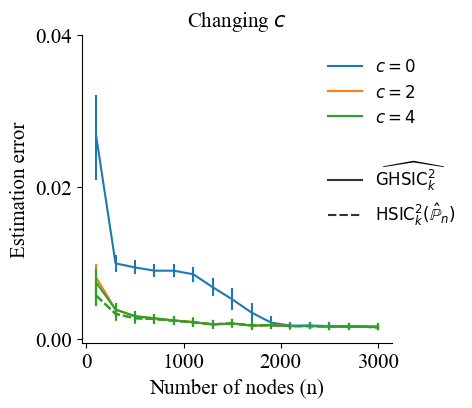

In [ ]:
fig, ax = plt.subplots(figsize=(4, 4))

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)


params = {'legend.fontsize': 12,
          'axes.labelsize': 15,
          'axes.titlesize': 15,
          'xtick.labelsize': 15,
          'ytick.labelsize': 15,
          'text.usetex': False,
          'font.family': "Times New Roman",
          'text.latex.preamble': r'\usepackage{amsfonts}'}
plt.rcParams.update(params)

#plt.plot(nodes, fit1, marker="*",linestyle='dashed',c='darkgray')
#plt.plot(nodes, fit2, marker="*",linestyle='dashed',c='darkgray')
#plt.plot(nodes, fit3, marker="*",linestyle='dashed',c='darkgray')


g = sns.lineplot(
    data=df,
    x="node", y="val", hue="cate", style="type",
    err_style="bars"
)


#L=plt.legend([],[],frameon=False)
L=plt.legend(frameon=False,loc='upper center', bbox_to_anchor=(1, 1.05),fancybox=False, shadow=False)
L.get_texts()[0].set_text('')
#L.get_texts()[1].set_text(r'$\rho=0.1$')
#L.get_texts()[2].set_text(r'$\rho=0.5$')
#L.get_texts()[3].set_text(r'$\rho=0.9$')
#L.get_texts()[1].set_text(r'$\gamma=4$')
#L.get_texts()[2].set_text(r'$\gamma=2$')
#L.get_texts()[3].set_text(r'$\gamma=1$')
L.get_texts()[1].set_text(r'$c=0$')
L.get_texts()[2].set_text(r'$c=2$')
L.get_texts()[3].set_text(r'$c=4$')
L.get_texts()[4].set_text('')
L.get_texts()[5].set_text(r'$\widehat{\mathrm{GHSIC}_k^2}$')
L.get_texts()[6].set_text(r'$\mathrm{HSIC}_k^2(\hat{\mathbb{P}}_n)$')
#L.get_texts()[2].set_text(r'$\widehat{\mathrm{GHSIC}_k^2}$ ($d^{m}=\hat{\hat{d}}^{m}(n)$')
#L.get_texts()[3].set_text(r'$\widehat{\mathrm{GHSIC}_k^2}$ ($d^{m}=\hat{\hat{d}}^{m}_{d_0}(n)$')
#L.get_texts()[4].set_text(r'$\mathrm{HSIC}_k^2(\hat{\mathbb{P}}_n)$')

#ax.set_title(r'Changing $\rho$',fontsize=15)
#ax.set_title(r'Changing $\gamma$',fontsize=15)
ax.set_title(r'Changing $c$',fontsize=15)
#ax.set_title(r'$\gamma=1$',fontsize=15)
#ax.set_title('M=5',fontsize=15)

plt.ylim(-0.0005, 0.02)
#g.set(ylabel=None,yticks=[0,0.002,0.004])
#g.set(ylabel=None,yticks=[0,0.01,0.02])
g.set(ylabel=None,yticks=[0,0.02,0.04])

#g.set_yscale('log')
#g.set_xscale('log')

g.set(xlabel='Number of nodes (n)')
g.set(ylabel='Estimation error')
plt.savefig('./GHSIC_code/new_results/Compare_c.svg', format='svg',bbox_inches="tight")

In [ ]:
gcor0 = pd.read_csv("./GHSIC_code/sim_results/theta3/d0/gcor_d020_hathatd_time.csv")
del gcor0['Unnamed: 0']
gcor0.head()

,0,1,2,3,4,5,6,7,8,9,...,40,41,42,43,44,45,46,47,48,49
0,0.020029,0.018008,0.021870,0.031088,0.010933,0.022432,0.022897,0.019464,0.037871,0.021884,...,0.034492,0.023565,0.010197,0.020319,0.020052,0.019871,0.026544,0.020388,0.021227,0.021179
1,0.118743,0.110920,0.133695,0.136637,0.210510,0.230444,0.234135,0.299054,0.230093,0.207883,...,0.129524,0.136294,0.091090,0.154686,0.152259,0.162548,0.140890,0.117307,0.153644,0.162661
2,0.411639,0.425174,0.383870,0.687291,0.720668,0.365878,0.321731,0.434052,0.514288,0.367294,...,0.538221,0.364213,0.379847,0.409507,0.359439,0.821332,0.821197,0.370090,0.364552,0.393639
3,0.950424,0.733563,0.739298,1.400104,0.733093,0.762671,0.721705,0.748924,0.989885,1.451929,...,0.773783,0.715510,1.382341,0.934111,0.764652,0.981948,0.968914,1.354500,1.238541,0.779692
4,1.773375,3.209531,1.343701,1.690762,2.393801,1.289543,1.657576,3.185238,1.263578,1.235004,...,1.237203,1.320022,2.243190,1.688746,1.257289,2.296119,1.683766,1.388079,4.384719,1.690038


In [ ]:
gcor1 = pd.read_csv("./GHSIC_code/sim_results/theta3/d0/gcor_d020_hathatd_fast_time.csv")
del gcor1['Unnamed: 0']
gcor1.head()

,0,1,2,3,4,5,6,7,8,9,...,40,41,42,43,44,45,46,47,48,49
0,0.012650,0.004713,0.011791,0.013439,0.004787,0.010257,0.010063,0.012165,0.010113,0.010575,...,0.009913,0.008571,0.004639,0.014954,0.011497,0.011687,0.009325,0.012263,0.011728,0.013005
1,0.010012,0.009389,0.009516,0.017011,0.028676,0.027570,0.023533,0.033991,0.023829,0.028921,...,0.009014,0.015919,0.019365,0.017954,0.012892,0.018433,0.009450,0.021464,0.015409,0.016428
2,0.019074,0.021685,0.018008,0.045393,0.043636,0.021954,0.018765,0.065671,0.017723,0.022378,...,0.021688,0.017881,0.021360,0.022223,0.017623,0.043868,0.045120,0.023536,0.025974,0.025498
3,0.034278,0.030115,0.039118,0.062069,0.032543,0.027554,0.031379,0.030551,0.072258,0.031983,...,0.029126,0.030133,0.070722,0.027684,0.026447,0.027211,0.033971,0.063375,0.034769,0.027817
4,0.039322,0.092826,0.052402,0.036391,0.081501,0.040552,0.042126,0.068357,0.040043,0.042232,...,0.042283,0.039709,0.051687,0.036942,0.040999,0.036729,0.046647,0.053669,0.057528,0.043842


In [ ]:
gcor2 = pd.read_csv("./GHSIC_code/sim_results/theta3/d0/gcor_d020_hatK_time.csv")
del gcor2['Unnamed: 0']
gcor2.head()

,0,1,2,3,4,5,6,7,8,9,...,40,41,42,43,44,45,46,47,48,49
0,0.000674,0.000344,0.000373,0.000398,0.000312,0.000414,0.000384,0.000361,0.000368,0.000366,...,0.000290,0.000335,0.000223,0.000404,0.000410,0.000380,0.000356,0.000382,0.000374,0.000375
1,0.000542,0.000482,0.000425,0.000423,0.004098,0.000410,0.001213,0.000388,0.000464,0.000446,...,0.000369,0.000437,0.000428,0.000417,0.000433,0.000417,0.000458,0.000512,0.000553,0.000554
2,0.000840,0.000859,0.000695,0.002294,0.000787,0.000871,0.001753,0.000867,0.000648,0.000875,...,0.000691,0.000692,0.000724,0.000676,0.000642,0.000693,0.000816,0.000906,0.000865,0.000732
3,0.001087,0.001082,0.003205,0.001117,0.001720,0.001576,0.001257,0.001055,0.001430,0.001352,...,0.001059,0.001027,0.001463,0.001074,0.001416,0.000982,0.001014,0.001107,0.001077,0.001127
4,0.001953,0.003811,0.001812,0.001475,0.001362,0.001497,0.001345,0.001347,0.001323,0.001352,...,0.001344,0.001984,0.001477,0.001341,0.001904,0.001482,0.001680,0.001659,0.002071,0.004171


In [ ]:
gcor3 = pd.read_csv("./GHSIC_code/sim_results/theta3/d0/gcor_d020_GHSIC_time.csv")
del gcor3['Unnamed: 0']
gcor3.head()

,0,1,2,3,4,5,6,7,8,9,...,40,41,42,43,44,45,46,47,48,49
0,0.000309,0.000312,0.000309,0.000326,0.000330,0.000392,0.000298,0.000294,0.000331,0.000334,...,0.000304,0.000317,0.000330,0.000365,0.000296,0.000297,0.000299,0.000296,0.000331,0.000341
1,0.000721,0.000707,0.000695,0.000596,0.000659,0.009125,0.000645,0.000677,0.000760,0.000840,...,0.000602,0.000700,0.000617,0.000623,0.000602,0.000666,0.000629,0.000714,0.005103,0.000691
2,0.001703,0.001606,0.001267,0.005743,0.008789,0.001735,0.001347,0.013751,0.001379,0.002127,...,0.001454,0.001364,0.001354,0.001420,0.001276,0.001577,0.001533,0.001573,0.001539,0.001761
3,0.006780,0.002263,0.005185,0.011101,0.008867,0.004366,0.002558,0.002211,0.011584,0.007871,...,0.002198,0.007090,0.015663,0.002232,0.003386,0.002230,0.002762,0.016182,0.002329,0.002508
4,0.005624,0.013918,0.004112,0.004184,0.011710,0.004764,0.012472,0.005142,0.008450,0.003970,...,0.008236,0.005721,0.004256,0.003890,0.004880,0.003204,0.015284,0.005432,0.013668,0.005579


In [ ]:
hcor = pd.read_csv("./GHSIC_code/sim_results/theta3/d0/hcor_d020_time.csv")
del hcor['Unnamed: 0']
hcor.head()

,0,1,2,3,4,5,6,7,8,9,...,40,41,42,43,44,45,46,47,48,49
0,0.000691,0.000667,0.000665,0.000721,0.000674,0.000743,0.000638,0.000647,0.000666,0.000693,...,0.000625,0.000666,0.000664,0.000752,0.000643,0.000665,0.000623,0.000645,0.000657,0.000673
1,0.001432,0.001463,0.001656,0.001264,0.001351,0.009862,0.001284,0.001379,0.006358,0.001706,...,0.001233,0.001450,0.001270,0.001301,0.001272,0.005764,0.001262,0.001438,0.006052,0.006258
2,0.003346,0.008407,0.002590,0.007355,0.016030,0.003417,0.002811,0.021195,0.002782,0.010228,...,0.002869,0.002730,0.002929,0.002697,0.002520,0.010070,0.002921,0.008332,0.002947,0.008760
3,0.009745,0.004450,0.012289,0.016546,0.018325,0.008665,0.010106,0.004639,0.030772,0.016194,...,0.004471,0.009426,0.026328,0.004736,0.006856,0.004816,0.017532,0.024991,0.004982,0.005099
4,0.011541,0.024787,0.013050,0.008223,0.024946,0.009388,0.023049,0.014247,0.016673,0.012870,...,0.012402,0.011277,0.008185,0.008053,0.009678,0.006716,0.026586,0.010358,0.024787,0.010725


In [36]:
gcorr_list0 = []
gcorr_list1 = []
gcorr_list2 = []
gcorr_list3 = []
hcorr_list = []

for i in range(50):
    gcorr_list0 = gcorr_list0 + list(gcor0[str(i)])
    gcorr_list1 = gcorr_list1 + list(gcor1[str(i)])
    gcorr_list2 = gcorr_list2 + list(gcor2[str(i)])
    gcorr_list3 = gcorr_list3 + list(gcor3[str(i)])
    hcorr_list = hcorr_list + list(hcor[str(i)])
    
len(gcorr_list1)

750

In [37]:
nodes = [100,300,500,700,900,1100,1300,1500,1700,1900,2100,2300,2500,2700,3000]
#nodes = node

df0 = pd.DataFrame(
  data ={
  'node':nodes*50,
  'val':gcorr_list0,
  'cate':['Est_tau0']*(15*50)
  }
)
df0.head()

,node,val,cate
0,100,0.020029,Est_tau0
1,300,0.118743,Est_tau0
2,500,0.411639,Est_tau0
3,700,0.950424,Est_tau0
4,900,1.773375,Est_tau0


In [38]:
df1 = pd.DataFrame(
  data ={
  'node':nodes*50,
  'val':gcorr_list1,
  'cate':['Est_tau']*(15*50)
  }
)
df1.head()

,node,val,cate
0,100,0.012650,Est_tau
1,300,0.010012,Est_tau
2,500,0.019074,Est_tau
3,700,0.034278,Est_tau
4,900,0.039322,Est_tau


In [39]:
df2 = pd.DataFrame(
  data ={
  'node':nodes*50,
  'val':gcorr_list2,
  'cate':['Est_K']*(15*50)
  }
)
df2.head()

,node,val,cate
0,100,0.000674,Est_K
1,300,0.000542,Est_K
2,500,0.000840,Est_K
3,700,0.001087,Est_K
4,900,0.001953,Est_K


In [40]:
df3 = pd.DataFrame(
  data ={
  'node':nodes*50,
  'val':gcorr_list3,
  'cate':['Est_HSIC']*(15*50)
  }
)
df3.head()

,node,val,cate
0,100,0.000309,Est_HSIC
1,300,0.000721,Est_HSIC
2,500,0.001703,Est_HSIC
3,700,0.006780,Est_HSIC
4,900,0.005624,Est_HSIC


In [41]:
df4 = pd.DataFrame(
  data ={
  'node':nodes*50,
  'val':hcorr_list,
  'cate':['Hcorr']*(15*50)
  }
)
df4.head()

,node,val,cate
0,100,0.000691,Hcorr
1,300,0.001432,Hcorr
2,500,0.003346,Hcorr
3,700,0.009745,Hcorr
4,900,0.011541,Hcorr


In [42]:
df = pd.concat([df0,df1,df2,df3,df4],axis = 0)
df = df.reset_index(drop=True)
df.head()

,node,val,cate
0,100,0.020029,Est_tau0
1,300,0.118743,Est_tau0
2,500,0.411639,Est_tau0
3,700,0.950424,Est_tau0
4,900,1.773375,Est_tau0


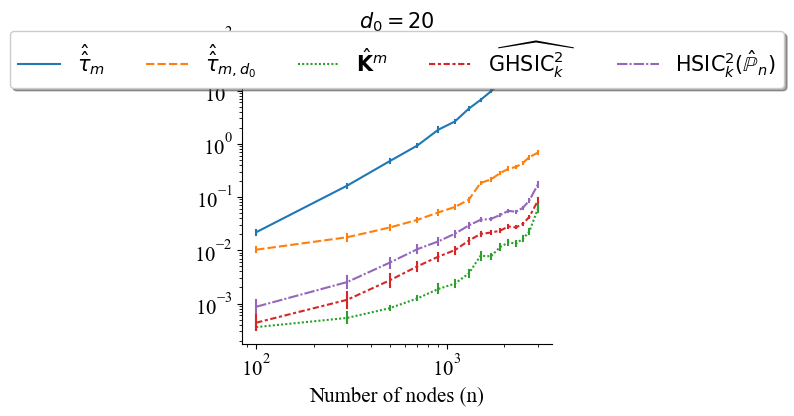

In [ ]:
fig, ax = plt.subplots(figsize=(4, 4))

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

params = {'legend.fontsize': 15,
          'axes.labelsize': 15,
          'axes.titlesize': 15,
          'xtick.labelsize': 15,
          'ytick.labelsize': 15,
          'text.usetex': False,
          'font.family': "Times New Roman",
          #"mathtext.fontset" : "stix",
          #"font.family": "sans-serif",
          #"font.sans-serif": "Helvetica",
          'text.latex.preamble': r'\usepackage{amsfonts,yhmath}'}
plt.rcParams.update(params)


g = sns.lineplot(
    data=df,
    x="node", y="val", hue="cate", style="cate",
    err_style="bars"
)

#L=plt.legend([],[],frameon=False)
L=plt.legend(frameon='False',loc='upper center', bbox_to_anchor=(0.5, 1.05),ncol=5, fancybox=True, shadow=True)
L.get_texts()[0].set_text(r'$\hat{\hat{\tau}}_m$')
L.get_texts()[1].set_text(r'$\hat{\hat{\tau}}_{m,d_0}$')
L.get_texts()[2].set_text(r'$\hat{\mathbf{K}}^m$')
L.get_texts()[3].set_text(r'$\widehat{\mathrm{GHSIC}_k^2}$')
L.get_texts()[4].set_text(r'$\mathrm{HSIC}_k^2(\hat{\mathbb{P}}_n)$')

g.set(xlabel='Number of nodes (n)')
#g.set(ylabel='Runtime (s)')
g.set(ylabel=None)

ax.set_title(r'$d_{0}=20$',fontsize=15)

g.set_xscale('log')
g.set_yscale('log')


plt.savefig('./GHSIC_code/sim_results/figs/Compare_d020_time_legend.svg', format='svg',bbox_inches="tight")

In [7]:
nodes = [50,100,150,200,250,300]

In [ ]:
df1 = pd.read_csv('./GHSIC_code/new_results/exp-2/pow_dhat_M5_cov4.csv')
del df1['Unnamed: 0']

In [ ]:
df2 = pd.read_csv('./GHSIC_code/new_results/exp-2/pow_dhathat_M5_cov4.csv')
del df2['Unnamed: 0']

In [ ]:
df3 = pd.read_csv('./GHSIC_code/new_results/exp-2/pow_dhathat_fast_M5_cov4.csv')
del df3['Unnamed: 0']

In [72]:
pow_list0 = []
pow_list1 = []
pow_list2 = []

for i in range(20):
    pow_list0 = pow_list0 + list(df1[str(i)])
    pow_list1 = pow_list1 + list(df2[str(i)])
    pow_list2 = pow_list2 + list(df3[str(i)])
    
len(pow_list0)

120

In [73]:
df11 = pd.DataFrame(
  data ={
  'node':nodes*20,
  'val':pow_list0,
  'cate':['hatd']*(6*20)
  }
)
df11.head()

,node,val,cate
0,50,1.0,hatd
1,100,1.0,hatd
2,150,1.0,hatd
3,200,1.0,hatd
4,250,1.0,hatd


In [74]:
df12 = pd.DataFrame(
  data ={
  'node':nodes*20,
  'val':pow_list1,
  'cate':['hathatd']*(6*20)
  }
)
df12.head()

,node,val,cate
0,50,1.0,hathatd
1,100,1.0,hathatd
2,150,1.0,hathatd
3,200,1.0,hathatd
4,250,1.0,hathatd


In [75]:
df13 = pd.DataFrame(
  data ={
  'node':nodes*20,
  'val':pow_list2,
  'cate':['hathatd_fast']*(6*20)
  }
)
df13.head()

,node,val,cate
0,50,1.0,hathatd_fast
1,100,1.0,hathatd_fast
2,150,1.0,hathatd_fast
3,200,1.0,hathatd_fast
4,250,1.0,hathatd_fast


In [76]:
df = pd.concat([df11,df12,df13],axis = 0)
df = df.reset_index(drop=True)

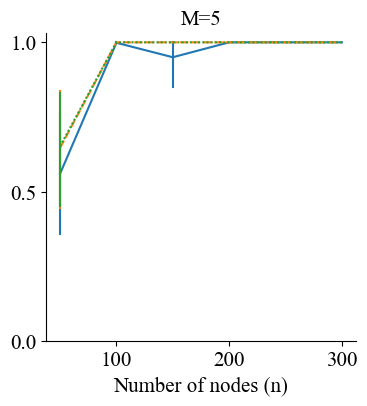

In [ ]:
fig, ax = plt.subplots(figsize=(4, 4))

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)


params = {'legend.fontsize': 15,
          'axes.labelsize': 15,
          'axes.titlesize': 15,
          'xtick.labelsize': 15,
          'ytick.labelsize': 15,
          'text.usetex': False,
          'font.family': "Times New Roman",
          'text.latex.preamble': r'\usepackage{amsfonts}'}
plt.rcParams.update(params)

g = sns.lineplot(
    data=df,
    x="node", y="val", hue="cate", style="cate",
    err_style="bars"
)


L=plt.legend([],[],frameon=False)
#L=plt.legend(frameon='False',loc='upper center', bbox_to_anchor=(0.5, 1.05),ncol=3, fancybox=True, shadow=True)
#L.get_texts()[0].set_text(r'$\hat{\tau}_m$')
#L.get_texts()[1].set_text(r'$\hat{\hat{\tau}}_m$')
#L.get_texts()[2].set_text(r'$\hat{\hat{\tau}}_{m,d_0}$')

ax.set_title('M=5',fontsize=15)

g.set(ylabel=None,yticks=[0,0.5,1])

g.set(xlabel='Number of nodes (n)')
#g.set(ylabel='Power')

plt.savefig('./GHSIC_code/new_results/figs/Compare_pow_M5_cov4.svg', format='svg',bbox_inches="tight")